# Phase 2 -- Dataset Selection & Initial Understanding
## AI-Powered Customer Churn & Retention System

### Phase Objective
The goal of Phase 2 is to acquire the raw Telco Customer Churn dataset, verify its integrity, document its schema and characteristics, and perform an exhaustive initial data understanding without applying any cleaning, preprocessing, feature engineering, or model training.

> **Scope Boundaries (Phase 2 Rule):**
> - The raw dataset in `data/raw/Telco-Customer-Churn.csv` remains strictly untouched.
> - No missing-value imputation, categorical encoding, feature scaling, outlier filtering, or train/test splitting is performed in this phase.


In [1]:
# Import required libraries for exploration and visualization
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual styles
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (8, 4)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

print("Libraries imported successfully.")
print(f"Pandas version: {pd.__version__}")
print(f"Numpy version:  {np.__version__}")


Libraries imported successfully.
Pandas version: 3.0.6
Numpy version:  2.5.3


## 1. Load the Raw Dataset
We load the dataset directly from `data/raw/Telco-Customer-Churn.csv`. This file is the exact immutable source data obtained from the official IBM Telco churn repository.


In [2]:
# Path to the raw, untouched dataset
# Supports running both from the notebooks/ directory and project root
raw_data_path = os.path.join("..", "data", "raw", "Telco-Customer-Churn.csv")
if not os.path.exists(raw_data_path):
    raw_data_path = os.path.join("data", "raw", "Telco-Customer-Churn.csv")

# Load without modifying any types or values
df = pd.read_csv(raw_data_path)

print(f"Loaded dataset from: {raw_data_path}")
print(f"Dataset Shape: {df.shape[0]} rows x {df.shape[1]} columns")


Loaded dataset from: ..\data\raw\Telco-Customer-Churn.csv
Dataset Shape: 7043 rows x 21 columns


## 2. Initial Inspection: Head and Tail
Inspect the first 5 and last 5 rows of the dataset to verify structure, column headers, and data formatting.


In [3]:
# Display first 5 rows
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Display last 5 rows
df.tail()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


## 3. Dataset Dimensions, Column Names, and Data Types


In [5]:
# Number of rows and columns
n_rows, n_cols = df.shape
print(f"Total Rows:    {n_rows}")
print(f"Total Columns: {n_cols}")

print("\nList of all column names:")
for idx, col in enumerate(df.columns, 1):
    print(f"  {idx:2d}. {col}")


Total Rows:    7043
Total Columns: 21

List of all column names:
   1. customerID
   2. gender
   3. SeniorCitizen
   4. Partner
   5. Dependents
   6. tenure
   7. PhoneService
   8. MultipleLines
   9. InternetService
  10. OnlineSecurity
  11. OnlineBackup
  12. DeviceProtection
  13. TechSupport
  14. StreamingTV
  15. StreamingMovies
  16. Contract
  17. PaperlessBilling
  18. PaymentMethod
  19. MonthlyCharges
  20. TotalCharges
  21. Churn


In [6]:
# Display concise schema info and inferred data types
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 4. Basic Numerical Summary Statistics
Summarize central tendency, dispersion, and range for initial numeric columns.


In [7]:
# Summary statistics for recognized numeric columns
df.describe().T


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


## 5. Missing Values and Duplicate Rows
We evaluate both standard explicit nulls (`NaN` / `None`) and check for duplicate rows across the entire dataset.


In [8]:
# Check for explicit missing/null values
missing_counts = df.isnull().sum()
missing_pct = (missing_counts / len(df)) * 100

missing_summary = pd.DataFrame({
    'Missing Count': missing_counts,
    'Missing Percentage (%)': missing_pct.round(2)
})

print("Explicit Null Value Summary:")
print(missing_summary)


Explicit Null Value Summary:
                  Missing Count  Missing Percentage (%)
customerID                    0                     0.0
gender                        0                     0.0
SeniorCitizen                 0                     0.0
Partner                       0                     0.0
Dependents                    0                     0.0
tenure                        0                     0.0
PhoneService                  0                     0.0
MultipleLines                 0                     0.0
InternetService               0                     0.0
OnlineSecurity                0                     0.0
OnlineBackup                  0                     0.0
DeviceProtection              0                     0.0
TechSupport                   0                     0.0
StreamingTV                   0                     0.0
StreamingMovies               0                     0.0
Contract                      0                     0.0
PaperlessBilling   

In [9]:
# Check for duplicate rows across all columns
dup_count = df.duplicated().sum()
print(f"Number of duplicate rows: {dup_count}")


Number of duplicate rows: 0


## 6. Categorical Columns & Unique Values
We inspect the cardinality and unique categories for each text/object column.


In [10]:
# Identify non-numeric columns
cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()
print(f"Identified {len(cat_cols)} non-numeric columns:\n")

for col in cat_cols:
    unique_vals = df[col].unique()
    n_unique = df[col].nunique()
    if n_unique <= 10:
        print(f"• {col:<18} ({n_unique} unique): {list(unique_vals)}")
    else:
        print(f"• {col:<18} ({n_unique} unique): [High cardinality: e.g. {list(unique_vals[:4])}...]")


Identified 18 non-numeric columns:

• customerID         (7043 unique): [High cardinality: e.g. ['7590-VHVEG', '5575-GNVDE', '3668-QPYBK', '7795-CFOCW']...]
• gender             (2 unique): ['Female', 'Male']
• Partner            (2 unique): ['Yes', 'No']
• Dependents         (2 unique): ['No', 'Yes']
• PhoneService       (2 unique): ['No', 'Yes']
• MultipleLines      (3 unique): ['No phone service', 'No', 'Yes']
• InternetService    (3 unique): ['DSL', 'Fiber optic', 'No']
• OnlineSecurity     (3 unique): ['No', 'Yes', 'No internet service']
• OnlineBackup       (3 unique): ['Yes', 'No', 'No internet service']
• DeviceProtection   (3 unique): ['No', 'Yes', 'No internet service']
• TechSupport        (3 unique): ['No', 'Yes', 'No internet service']
• StreamingTV        (3 unique): ['No', 'Yes', 'No internet service']
• StreamingMovies    (3 unique): ['No', 'Yes', 'No internet service']
• Contract           (3 unique): ['Month-to-month', 'One year', 'Two year']
• PaperlessBilling   (2 u

## 7. Target Column Identification & Distribution
- **Target Variable**: `Churn`
- **Definition**: Indicates whether the customer left within the last month (`Yes` vs `No`).


In [11]:
target_counts = df['Churn'].value_counts(dropna=False)
target_percentages = df['Churn'].value_counts(normalize=True, dropna=False) * 100

target_dist = pd.DataFrame({
    'Count': target_counts,
    'Percentage (%)': target_percentages.round(2)
})

print("Target ('Churn') Distribution:")
print(target_dist)


Target ('Churn') Distribution:
       Count  Percentage (%)
Churn                       
No      5174           73.46
Yes     1869           26.54


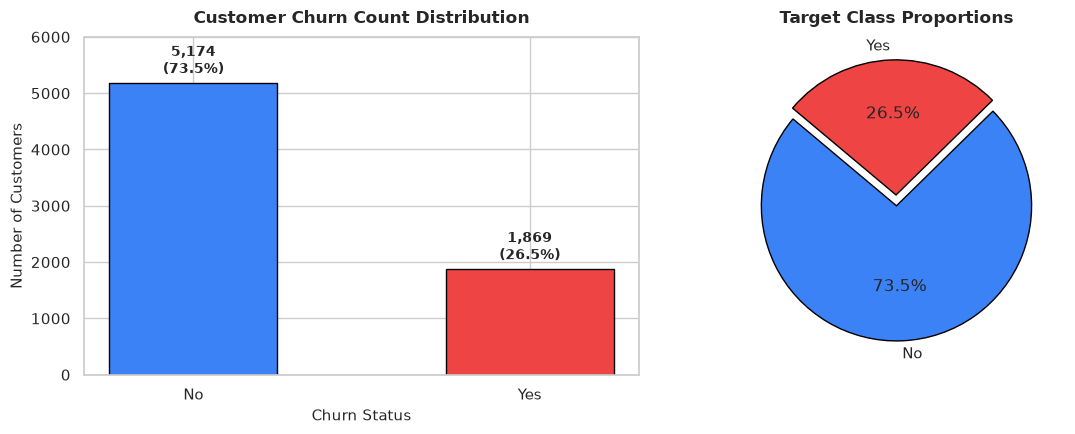

In [12]:
# Visualize the target distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Bar plot with count and percentage annotations
bars = axes[0].bar(target_dist.index, target_dist['Count'], color=['#3b82f6', '#ef4444'], width=0.5, edgecolor='black')
axes[0].set_title("Customer Churn Count Distribution", fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel("Churn Status", fontsize=11)
axes[0].set_ylabel("Number of Customers", fontsize=11)
axes[0].set_ylim(0, 6000)

for bar, count, pct in zip(bars, target_dist['Count'], target_dist['Percentage (%)']):
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, yval + 100, f"{count:,}\n({pct:.1f}%)", 
                 ha='center', va='bottom', fontsize=10, fontweight='bold')

# Pie chart
axes[1].pie(target_dist['Count'], labels=target_dist.index, autopct='%1.1f%%',
            startangle=140, colors=['#3b82f6', '#ef4444'], explode=(0, 0.08),
            wedgeprops={'edgecolor': 'black', 'linewidth': 1})
axes[1].set_title("Target Class Proportions", fontsize=12, fontweight='bold', pad=10)

plt.tight_layout()
plt.show()


## 8. Identification of Identifiers & Data Type Mismatches

### 8.1 Identifier Columns
- `customerID` has **7,043 unique values** across 7,043 total rows (100% unique cardinality).
- It serves as a customer account primary key and carries no predictive behavioral pattern. Including it in predictive models would risk memorization and overfitting. It must be excluded from feature sets.

### 8.2 Numeric Columns Stored as Text: `TotalCharges`
- `TotalCharges` is currently stored as `object` (text/string) rather than `float64`.
- Let's inspect why this happened.


In [13]:
# Check values in TotalCharges that cannot be directly parsed as float
whitespace_mask = df['TotalCharges'].str.strip() == ''
n_whitespace = whitespace_mask.sum()
print(f"Total rows where TotalCharges is whitespace/empty: {n_whitespace}")

# Display all rows with whitespace in TotalCharges
print("\nRows with whitespace in TotalCharges:")
df[whitespace_mask][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'PaymentMethod', 'Churn']]


Total rows where TotalCharges is whitespace/empty: 11

Rows with whitespace in TotalCharges:


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,PaymentMethod,Churn
488,4472-LVYGI,0,52.55,,Two year,Bank transfer (automatic),No
753,3115-CZMZD,0,20.25,,Two year,Mailed check,No
936,5709-LVOEQ,0,80.85,,Two year,Mailed check,No
1082,4367-NUYAO,0,25.75,,Two year,Mailed check,No
1340,1371-DWPAZ,0,56.05,,Two year,Credit card (automatic),No
3331,7644-OMVMY,0,19.85,,Two year,Mailed check,No
3826,3213-VVOLG,0,25.35,,Two year,Mailed check,No
4380,2520-SGTTA,0,20.00,,Two year,Mailed check,No
5218,2923-ARZLG,0,19.70,,One year,Mailed check,No
6670,4075-WKNIU,0,73.35,,Two year,Mailed check,No


### Key Observation on `TotalCharges`:
Every single one of the **11 rows** with whitespace in `TotalCharges` has **`tenure == 0`**.
These are new customers who enrolled but have not completed a billing cycle yet.
- In Phase 2, we leave this column completely untouched in the raw dataset.
- In Phase 3, this column will be converted to numeric, with these 11 rows appropriately handled (e.g., imputed as `0.0` to match 0 months of tenure).


## 9. Data Leakage Investigation

Data leakage occurs when predictive features contain information that would only become available during or **AFTER** the target event (churn) has occurred, or when features incorporate information from the future that would not be present at decision time.

### Systematic Feature-by-Feature Review:

| Column Category | Columns Evaluated | Leakage Assessment | Verdict |
| :--- | :--- | :--- | :--- |
| **Identifiers** | `customerID` | Random unique account string. No leakage, but carries high overfitting risk if not excluded. | **Exclude from features** |
| **Demographics** | `gender`, `SeniorCitizen`, `Partner`, `Dependents` | Stable demographic attributes known at customer signup. | **No leakage (Safe)** |
| **Account & Tenancy** | `tenure`, `Contract`, `PaperlessBilling`, `PaymentMethod` | Account profile attributes recorded continuously during subscription life. | **No leakage (Safe)** |
| **Services Subscribed** | `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` | Active service subscriptions during active tenure. Recorded prior to churn decision. | **No leakage (Safe)** |
| **Financial / Billing** | `MonthlyCharges`, `TotalCharges` | `MonthlyCharges` is current monthly bill rate. `TotalCharges` is historical cumulative billed amount up to the snapshot/exit point. Highly correlated with `tenure * MonthlyCharges`. Both reflect pre-churn billing. | **No leakage (Safe)** |
| **Post-Event Indicators** | *None present* in this 21-column dataset (e.g. no `Churn Reason`, `Cancellation Date`, `Churn Score`, or `Exit Interview` fields). | No post-event feedback or resolution fields exist in this raw dataset. | **No leakage** |
| **Target Variable** | `Churn` | The ground-truth outcome label. Must be separated into target vector $y$. | **Target Variable** |

**Conclusion**: There are **no post-event leakage columns** present in this 21-column raw Telco dataset.


## 10. Comprehensive Data Dictionary
The table below documents all 21 columns in the raw dataset, their types, descriptions, roles, and exclusion rationale.


In [14]:
data_dict_records = [
    {"Column": "customerID", "Raw Type": "object (str)", "Category": "Categorical (ID)", "Description": "Unique alphanumeric identifier for each customer account", "Model Role": "Exclude", "Rationale": "Unique key (100% unique); causes data memorization and overfitting."},
    {"Column": "gender", "Raw Type": "object (str)", "Category": "Categorical", "Description": "Customer gender (Female, Male)", "Model Role": "Feature", "Rationale": "Demographic baseline feature."},
    {"Column": "SeniorCitizen", "Raw Type": "int64", "Category": "Categorical (Binary)", "Description": "Indicates if customer is a senior citizen (1: Yes, 0: No)", "Model Role": "Feature", "Rationale": "Demographic segment indicator."},
    {"Column": "Partner", "Raw Type": "object (str)", "Category": "Categorical (Binary)", "Description": "Whether the customer has a partner (Yes, No)", "Model Role": "Feature", "Rationale": "Household status feature."},
    {"Column": "Dependents", "Raw Type": "object (str)", "Category": "Categorical (Binary)", "Description": "Whether the customer has dependents (Yes, No)", "Model Role": "Feature", "Rationale": "Household dependency indicator."},
    {"Column": "tenure", "Raw Type": "int64", "Category": "Numerical (Discrete)", "Description": "Number of months customer has stayed with the company", "Model Role": "Feature", "Rationale": "Core loyalty/longevity metric; strong churn predictor."},
    {"Column": "PhoneService", "Raw Type": "object (str)", "Category": "Categorical (Binary)", "Description": "Whether the customer has home phone service (Yes, No)", "Model Role": "Feature", "Rationale": "Service subscription baseline."},
    {"Column": "MultipleLines", "Raw Type": "object (str)", "Category": "Categorical", "Description": "Whether customer has multiple lines (No phone service, No, Yes)", "Model Role": "Feature", "Rationale": "Service depth indicator."},
    {"Column": "InternetService", "Raw Type": "object (str)", "Category": "Categorical", "Description": "Customer internet service provider (DSL, Fiber optic, No)", "Model Role": "Feature", "Rationale": "Key service tier; known differentiator of churn risk."},
    {"Column": "OnlineSecurity", "Raw Type": "object (str)", "Category": "Categorical", "Description": "Whether customer has online security add-on (Yes, No, No internet service)", "Model Role": "Feature", "Rationale": "Value-added service engagement."},
    {"Column": "OnlineBackup", "Raw Type": "object (str)", "Category": "Categorical", "Description": "Whether customer has online backup add-on (Yes, No, No internet service)", "Model Role": "Feature", "Rationale": "Value-added service engagement."},
    {"Column": "DeviceProtection", "Raw Type": "object (str)", "Category": "Categorical", "Description": "Whether customer has tech device protection (Yes, No, No internet service)", "Model Role": "Feature", "Rationale": "Value-added service engagement."},
    {"Column": "TechSupport", "Raw Type": "object (str)", "Category": "Categorical", "Description": "Whether customer has premium tech support (Yes, No, No internet service)", "Model Role": "Feature", "Rationale": "Critical support service; highly correlated with retention."},
    {"Column": "StreamingTV", "Raw Type": "object (str)", "Category": "Categorical", "Description": "Whether customer streams third-party TV programs (Yes, No, No internet service)", "Model Role": "Feature", "Rationale": "Media entertainment product adoption."},
    {"Column": "StreamingMovies", "Raw Type": "object (str)", "Category": "Categorical", "Description": "Whether customer streams movies (Yes, No, No internet service)", "Model Role": "Feature", "Rationale": "Media entertainment product adoption."},
    {"Column": "Contract", "Raw Type": "object (str)", "Category": "Categorical", "Description": "Contract term commitment (Month-to-month, One year, Two year)", "Model Role": "Feature", "Rationale": "Commitment horizon; one of the strongest churn determinants."},
    {"Column": "PaperlessBilling", "Raw Type": "object (str)", "Category": "Categorical (Binary)", "Description": "Whether customer opted for paperless billing (Yes, No)", "Model Role": "Feature", "Rationale": "Billing preference channel."},
    {"Column": "PaymentMethod", "Raw Type": "object (str)", "Category": "Categorical", "Description": "Payment method (Electronic check, Mailed check, Bank transfer, Credit card)", "Model Role": "Feature", "Rationale": "Payment friction and automation indicator."},
    {"Column": "MonthlyCharges", "Raw Type": "float64", "Category": "Numerical (Continuous)", "Description": "Amount charged to customer monthly in USD", "Model Role": "Feature", "Rationale": "Price sensitivity and cost burden metric."},
    {"Column": "TotalCharges", "Raw Type": "object (str)", "Category": "Numerical (Continuous)", "Description": "Total amount charged to customer over account lifetime", "Model Role": "Feature (Needs Type Cast)", "Rationale": "Stored as string due to 11 empty space strings (' '); must cast to float in Phase 3."},
    {"Column": "Churn", "Raw Type": "object (str)", "Category": "Categorical (Binary)", "Description": "Whether customer churned in the previous month (Yes, No)", "Model Role": "Target", "Rationale": "Ground-truth target variable for binary classification."}
]

data_dict_df = pd.DataFrame(data_dict_records)
# Display formatted dictionary
from IPython.display import display, HTML
display(HTML(data_dict_df.to_html(index=False)))


Column,Raw Type,Category,Description,Model Role,Rationale
customerID,object (str),Categorical (ID),Unique alphanumeric identifier for each customer account,Exclude,Unique key (100% unique); causes data memorization and overfitting.
gender,object (str),Categorical,"Customer gender (Female, Male)",Feature,Demographic baseline feature.
SeniorCitizen,int64,Categorical (Binary),"Indicates if customer is a senior citizen (1: Yes, 0: No)",Feature,Demographic segment indicator.
Partner,object (str),Categorical (Binary),"Whether the customer has a partner (Yes, No)",Feature,Household status feature.
Dependents,object (str),Categorical (Binary),"Whether the customer has dependents (Yes, No)",Feature,Household dependency indicator.
tenure,int64,Numerical (Discrete),Number of months customer has stayed with the company,Feature,Core loyalty/longevity metric; strong churn predictor.
PhoneService,object (str),Categorical (Binary),"Whether the customer has home phone service (Yes, No)",Feature,Service subscription baseline.
MultipleLines,object (str),Categorical,"Whether customer has multiple lines (No phone service, No, Yes)",Feature,Service depth indicator.
InternetService,object (str),Categorical,"Customer internet service provider (DSL, Fiber optic, No)",Feature,Key service tier; known differentiator of churn risk.
OnlineSecurity,object (str),Categorical,"Whether customer has online security add-on (Yes, No, No internet service)",Feature,Value-added service engagement.


## 11. Initial Data Quality Findings

Without modifying or altering the raw dataset, our Phase 2 initial data understanding revealed the following factual findings:

1. **Dataset Size & Completeness**:
   - The raw dataset contains **7,043 rows** and **21 columns**.
   - Standard null detection (`df.isnull().sum()`) returns **0 missing values** across all columns.

2. **Hidden Missing Values in `TotalCharges`**:
   - `TotalCharges` is stored as an `object` (string) data type rather than a floating-point numeric.
   - There are **11 rows** containing a blank space string (`" "`).
   - Every single one of these 11 rows corresponds to a customer with **`tenure == 0`** and **`Churn == 'No'`**.
   - These are brand-new customers who have not yet reached their first billing cycle. In Phase 3, these should be cast to numeric with blank strings converted to `0.0`.

3. **Identifier Column (`customerID`)**:
   - `customerID` has **7,043 unique values** (100% uniqueness). It is a pure record identifier and must be excluded from modeling to avoid overfitting.

4. **Duplicate Records**:
   - There are **0 duplicate rows** in the dataset.

5. **Target Class Imbalance**:
   - Target variable `Churn` contains two classes:
     - `No`: **5,174 customers (73.46%)**
     - `Yes`: **1,869 customers (26.54%)**
   - The dataset exhibits moderate class imbalance (~2.77:1 ratio). Evaluation metrics must focus on PR-AUC, ROC-AUC, Precision, Recall, and F1-score rather than raw accuracy.

6. **Data Leakage Check**:
   - No post-churn fields (such as churn reason, exit survey notes, or churn timestamps) are present in this dataset.
   - All 19 feature columns reflect attributes known prior to or at the moment of the churn decision.

7. **Categorical Structure**:
   - 16 categorical/discrete columns: 2 demographic binary, 1 demographic indicator (`SeniorCitizen`), 9 service features with shared `'No internet service'` or `'No phone service'` sub-categories, 3 contract/billing features, and 1 target.
   - In Phase 3, redundant sub-categories (e.g. `'No internet service'` vs `'No'`) can be addressed uniformly during encoding.

---
*End of Phase 2 -- Data Understanding. The raw data remains 100% intact.*
